In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Usted dirige, por parte de la propiedad, un proyecto ejecutado por un contratista principal. El cuadro de prelaciones, las duraciones planificadas (semanas) y el presupuesto de cada actividad (BAC, k€) se adjuntan; el coste planificado de cada actividad se reparte uniformemente en su duración. El plazo contractual es de 19 semanas, con una penalización de 5 k€ por semana de retraso. Al contratista se le paga por certificaciones mensuales proporcionales al porcentaje de avance declarado de cada actividad.

In [4]:
#| tbl-cap: "Planificación del proyecto"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC
    ('A'     , '---'      , 8       , 30 ),
    ('B'     , '---'      , 4       , 10 ),
    ('C'     , 'A,B'      , 3       , 50 ),
    ('D'     , 'C'        , 5       , 50 ),
    ('E'     , 'C'        , 6       , 30 ),
    ('F'     , 'E'        , 2       , 60 ),
    ('G'     , 'D'        , 1       , 30 ),
    ('H'     , 'E,G'      , 1       , 30 ),
], columns=['activity', 'predecessor', 'duration', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC
activity,,,
A,---,8,30
B,---,4,10
C,"A,B",3,50
D,C,5,50
E,C,6,30
F,E,2,60
G,D,1,30
H,"E,G",1,30


Al final de la semana 10 el contratista envía su informe de avance (semanas trabajadas, coste incurrido en k€ y porcentaje realizado de cada actividad) y, el mismo día, llegan los mensajes siguientes.

In [5]:
#| tbl-cap: "Informe de avance del contratista (final de la semana 10)"
#| label: tbl-seguimiento
seguimiento = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 8              , 28, 100      ),
    ('B'     , 4              , 10, 100      ),
    ('C'     , 2              , 37, 67       ),
    ('D'     , 0              , 0 , 0        ),
    ('E'     , 0              , 0 , 0        ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 0              , 0 , 0        ),
    ('H'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento

,actual_duration,AC,performed
activity,,,
A,8,28,100
B,4,10,100
C,2,37,67
D,0,0,0
E,0,0,0
F,0,0,0
G,0,0,0
H,0,0,0


> **De: Contratista**
> Adjuntamos el informe de avance de la semana 10. El proyecto marcha según lo previsto y dentro de presupuesto. Solicitamos la certificación correspondiente, que incluye el 67 % de la actividad C (33.5 k€).

> **De: Jefe de equipo (supervisión de obra)**
> No estoy de acuerdo con el 67 % de C. He estado en obra esta semana: de lo que hay que hacer en C yo diría que está hecho **alrededor del 40 %**, aunque las horas y el gasto sí sean los que dicen. El resto de actividades me cuadra.

> **De: Comité de dirección**
> Para la reunión del lunes necesitamos un semáforo (verde/ámbar/rojo) de plazo y de coste, la previsión de coste final y la fecha de terminación prevista. Un número, no una explicación.

> **De: Dirección financiera**
> Si certificamos avance que no está ejecutado estamos adelantando dinero sin garantía; si retenemos sin motivo documentado, el contratista puede reclamar intereses de demora. Necesito un criterio.

> **De: Cliente**
> Recordamos que el hito de entrega en la semana 19 está vinculado a nuestros compromisos; cualquier desviación debe comunicarse por escrito en cuanto se conozca.

Responda a las preguntas siguientes **antes** de decidir. En la penúltima se le pide la decisión y cómo la comunicaría a cada uno de los implicados (contratista, jefe de equipo, comité de dirección, dirección financiera, cliente).

In [6]:
pregunta_1 = "1. Con los datos del informe del contratista, dibuje los Gantt del valor planificado, del valor ganado y del coste real, calcule PV, EV, AC, CV, SV, CPI y SPI y asigne el semáforo que pide el comité.  "
pregunta_2 = "2. Repita el cálculo sustituyendo el avance de C por la estimación del jefe de equipo. ¿Qué indicadores cambian y cuánto? ¿Por qué un único porcentaje mueve tanto los índices?  "
pregunta_3 = "3. Para las dos versiones, estime el coste final (EAC = BAC / CPI), la variación al final (VAC), el TCPI y la duración final (T / SPI). Añada una estimación directa del retraso a partir del ritmo real de C (es crítica) y el coste de la penalización asociada.  "
pregunta_4 = "4. ¿Qué certificaría este mes y con qué criterio? Cuantifique el sobrepago que supondría certificar el 67 % y proponga cómo verificar el avance físico (hitos, unidades de obra, reglas 0/100 o 50/50).  "
pregunta_5 = "5. Decida qué comunica al comité y redacte en tres o cuatro líneas la respuesta a cada implicado.  "
pregunta_6 = "6. ¿Qué debilidades del sistema de seguimiento revela el caso (quién mide el avance, cómo se liga al pago, qué verificación independiente hay) y cómo las corregiría en el contrato y en el procedimiento?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Con los datos del informe del contratista, dibuje los Gantt del valor planificado, del valor ganado y del coste real, calcule PV, EV, AC, CV, SV, CPI y SPI y asigne el semáforo que pide el comité.  

2. Repita el cálculo sustituyendo el avance de C por la estimación del jefe de equipo. ¿Qué indicadores cambian y cuánto? ¿Por qué un único porcentaje mueve tanto los índices?  

3. Para las dos versiones, estime el coste final (EAC = BAC / CPI), la variación al final (VAC), el TCPI y la duración final (T / SPI). Añada una estimación directa del retraso a partir del ritmo real de C (es crítica) y el coste de la penalización asociada.  

4. ¿Qué certificaría este mes y con qué criterio? Cuantifique el sobrepago que supondría certificar el 67 % y proponga cómo verificar el avance físico (hitos, unidades de obra, reglas 0/100 o 50/50).  

5. Decida qué comunica al comité y redacte en tres o cuatro líneas la respuesta a cada implicado.  

6. ¿Qué debilidades del sistema de seguimiento revela el caso (quién mide el avance, cómo se liga al pago, qué verificación independiente hay) y cómo las corregiría en el contrato y en el procedimiento?  

# Resolución

In [7]:
semana_control, plazo, penalizacion, actividad_discutida = 10, 19, 5, 'C'
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
BAC_total = float(datos_proyecto['BAC'].sum())
calendario_plan = proyecto.calendar(datos_proyecto['duration'])
def indicadores(seguimiento):
    datos_vg = pd.concat([datos_proyecto, seguimiento], axis=1)
    detalle = detalle_valor_ganado(datos_vg, calendario_plan, semana_control)
    PV, EV, AC = float(detalle['PV_i'].sum()), float(detalle['EV_i'].sum()), float(detalle['AC'].sum())
    return detalle, pd.Series({'PV': PV, 'EV': EV, 'AC': AC, 'CV': EV - AC, 'SV': EV - PV, 'CPI': EV / AC, 'SPI': EV / PV})
def semaforo(indice):
    return 'verde' if indice >= 0.95 else ('ámbar' if indice >= 0.85 else 'rojo')

In [ ]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

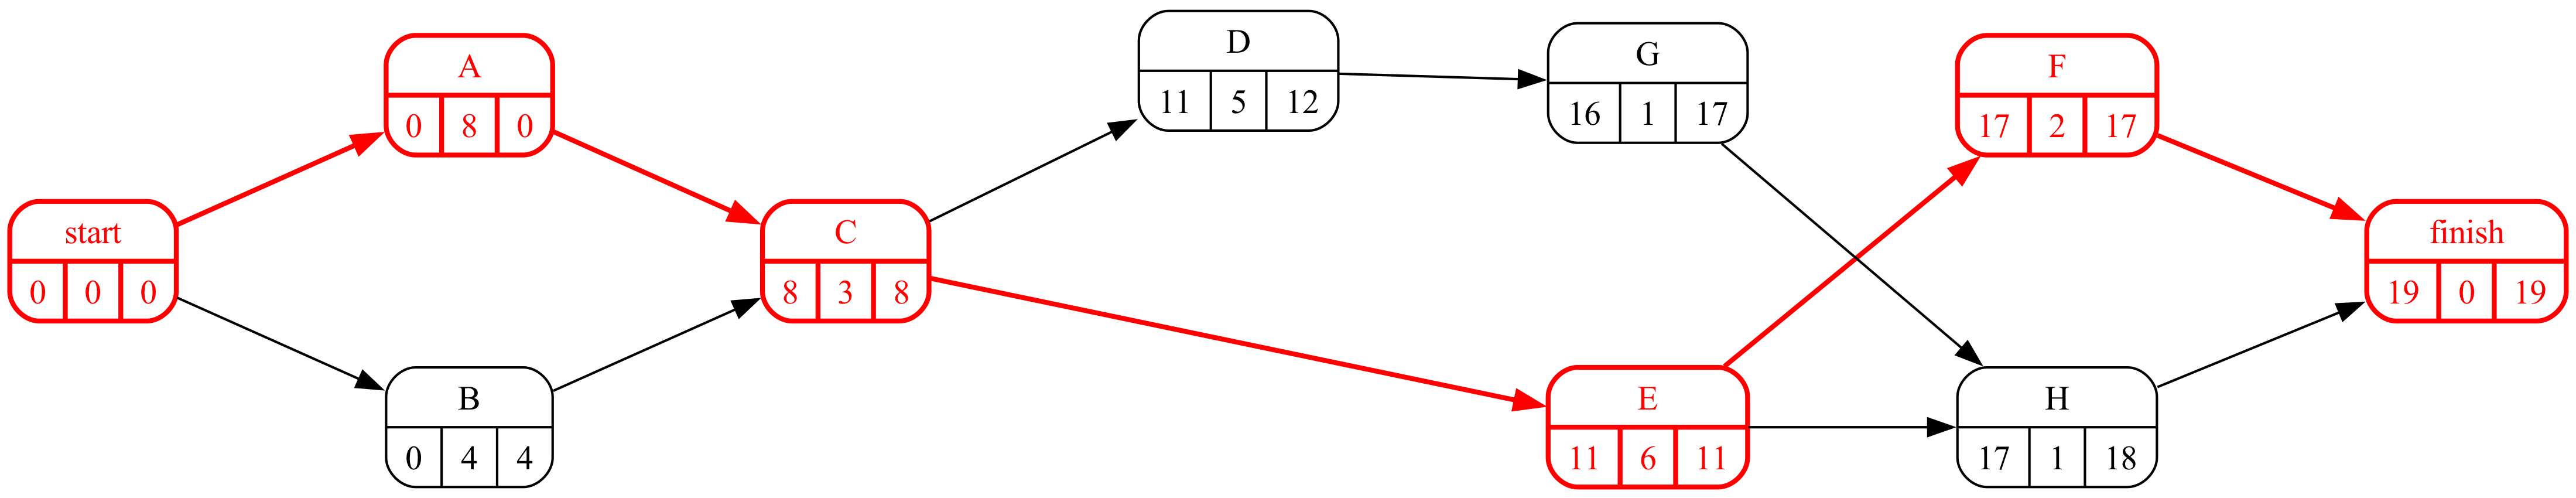

In [8]:
#| fig-cap: "Grafo Roy de la planificación"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Con los datos del informe del contratista, dibuje los Gantt del valor planificado, del valor ganado y del coste real, calcule PV, EV, AC, CV, SV, CPI y SPI y asigne el semáforo que pide el comité.  

In [10]:
datos_valor_ganado = pd.concat([datos_proyecto, seguimiento], axis=1)
vg = EarnedValue(proyecto)
gantts = vg.calcula_gantts(datos_valor_ganado, planned_durations_label='duration',
                           actual_durations_label='actual_duration', PV_label='BAC', AC_label='AC',
                           percentage_complete_label='performed', tikz=True,
                           params=dict(period_width=1, row_height=0.7, activity_relative_height=0.6, **GANTT_PARAMS,
                                       critical_background_color='white!90!green', regular_background_color='white!90!green',
                                       regular_text_color='black', critical_text_color='black'))

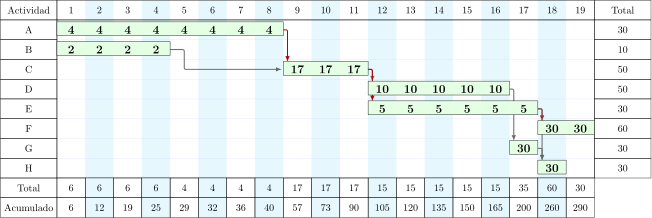

In [11]:
#| fig-cap: "PV: valor planificado"
#| label: fig-ganttPV
pinta_tikz(gantts['gantt_PV'])

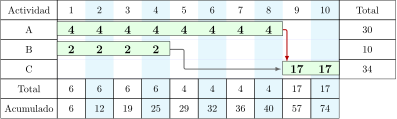

In [12]:
#| fig-cap: "EV: valor ganado según el informe del contratista"
#| label: fig-ganttEV
pinta_tikz(gantts['gantt_EV'])

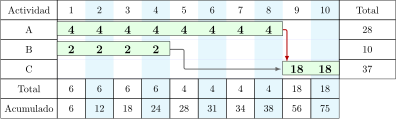

In [13]:
#| fig-cap: "AC: coste real"
#| label: fig-ganttAC
pinta_tikz(gantts['gantt_AC'])

In [14]:
#| tbl-cap: "PV, EV y AC actividad a actividad con el informe del contratista"
#| label: tbl-detalleContratista
detalle_rep, ind_rep = indicadores(seguimiento)
display(detalle_rep[['BAC', 'planificado hasta la semana', 'PV = BAC·fracción', 'realizado (%)', 'EV = BAC·%', 'AC']])
ind_rep.round(3).to_frame('informe del contratista').T

,BAC,planificado hasta la semana,PV = BAC·fracción,realizado (%),EV = BAC·%,AC
A,30.0,8 de 8,30·1.00 = 30.0,100,30·1.00 = 30.0,28.0
B,10.0,4 de 4,10·1.00 = 10.0,100,10·1.00 = 10.0,10.0
C,50.0,2 de 3,50·0.67 = 33.3,67,50·0.67 = 33.5,37.0
D,50.0,0 de 5,50·0.00 = 0.0,0,50·0.00 = 0.0,0.0
E,30.0,0 de 6,30·0.00 = 0.0,0,30·0.00 = 0.0,0.0
F,60.0,0 de 2,60·0.00 = 0.0,0,60·0.00 = 0.0,0.0
G,30.0,0 de 1,30·0.00 = 0.0,0,30·0.00 = 0.0,0.0
H,30.0,0 de 1,30·0.00 = 0.0,0,30·0.00 = 0.0,0.0


,PV,EV,AC,CV,SV,CPI,SPI
informe del contratista,73.333,73.5,75.0,-1.5,0.167,0.98,1.002


In [15]:
Markdown(f'''Semáforo con el informe: plazo **{semaforo(ind_rep["SPI"])}** (SPI = {ind_rep["SPI"]:.2f}), coste **{semaforo(ind_rep["CPI"])}** (CPI = {ind_rep["CPI"]:.2f}). Tal como lo cuenta el contratista, el proyecto va bien.''')

Semáforo con el informe: plazo **verde** (SPI = 1.00), coste **verde** (CPI = 0.98). Tal como lo cuenta el contratista, el proyecto va bien.

## Apartado 2

In [16]:
display(Markdown(pregunta_2))

2. Repita el cálculo sustituyendo el avance de C por la estimación del jefe de equipo. ¿Qué indicadores cambian y cuánto? ¿Por qué un único porcentaje mueve tanto los índices?  

In [17]:
#| tbl-cap: "Lo mismo con la estimación del jefe de equipo para la actividad discutida"
#| label: tbl-detalleReal
seguimiento_real = seguimiento.copy(); seguimiento_real.loc[actividad_discutida, 'performed'] = 40
detalle_real, ind_real = indicadores(seguimiento_real)
comparacion = pd.DataFrame({'informe del contratista': ind_rep, 'estimación del jefe de equipo': ind_real})
comparacion['diferencia'] = comparacion.iloc[:, 1] - comparacion.iloc[:, 0]
comparacion.round(3)

,informe del contratista,estimación del jefe de equipo,diferencia
PV,73.333,73.333,0.000
EV,73.500,60.000,-13.500
AC,75.000,75.000,0.000
CV,-1.500,-15.000,-13.500
SV,0.167,-13.333,-13.500
CPI,0.980,0.800,-0.180
SPI,1.002,0.818,-0.184


In [18]:
BAC_X = float(datos_proyecto.loc[actividad_discutida, 'BAC'])
Markdown(f'''Sólo cambia EV, en {ind_rep["EV"] - ind_real["EV"]:.1f} k€ (= {BAC_X:.0f} × (67 − 40) %), pero como PV y AC no se mueven, los dos índices caen a la vez: SPI = {ind_real["SPI"]:.2f} y CPI = {ind_real["CPI"]:.2f}; semáforo de plazo **{semaforo(ind_real["SPI"])}** y de coste **{semaforo(ind_real["CPI"])}**.''')

Sólo cambia EV, en 13.5 k€ (= 50 × (67 − 40) %), pero como PV y AC no se mueven, los dos índices caen a la vez: SPI = 0.82 y CPI = 0.80; semáforo de plazo **rojo** y de coste **rojo**.

Un único porcentaje mueve tanto los índices porque C es una actividad grande (50 k€ de BAC, el 17% del presupuesto) y porque a mitad de proyecto el valor ganado acumulado es pequeño: 14 k€ de valor «declarado y no hecho» pesan mucho sobre 60 k€ realmente ganados. El valor ganado es tan bueno como la medida del avance físico que lo alimenta.

## Apartado 3

In [19]:
display(Markdown(pregunta_3))

3. Para las dos versiones, estime el coste final (EAC = BAC / CPI), la variación al final (VAC), el TCPI y la duración final (T / SPI). Añada una estimación directa del retraso a partir del ritmo real de C (es crítica) y el coste de la penalización asociada.  

In [20]:
#| tbl-cap: "Previsiones de coste y plazo con las dos versiones"
#| label: tbl-previsiones
duracion_plan = int(proyecto.duration(datos_proyecto['duration']))
prev = pd.DataFrame({nombre: {'EAC = BAC / CPI': BAC_total / ind['CPI'], 'VAC = BAC − EAC': BAC_total - BAC_total / ind['CPI'],
                              'TCPI = (BAC − EV) / (BAC − AC)': (BAC_total - ind['EV']) / (BAC_total - ind['AC']),
                              'duración ≈ T / SPI': duracion_plan / ind['SPI'],
                              'penalización ≈ (T/SPI − T) × pen': max(0.0, duracion_plan / ind['SPI'] - plazo) * penalizacion}
                     for nombre, ind in (('informe del contratista', ind_rep), ('estimación del jefe de equipo', ind_real))})
prev.round(2)

,informe del contratista,estimación del jefe de equipo
EAC = BAC / CPI,295.92,362.50
VAC = BAC − EAC,-5.92,-72.50
TCPI = (BAC − EV) / (BAC − AC),1.01,1.07
duración ≈ T / SPI,18.96,23.22
penalización ≈ (T/SPI − T) × pen,0.00,21.11


In [21]:
semanas_trabajadas = int(seguimiento.loc[actividad_discutida, 'actual_duration'])
d_plan = int(datos_proyecto.loc[actividad_discutida, 'duration'])
semanas_ganadas = 40 / 100 * d_plan
retraso_directo = semanas_trabajadas - semanas_ganadas                 # el resto, al ritmo planificado
retraso_ritmo = semanas_trabajadas / (40 / 100) - d_plan           # el resto, al ritmo actual
Markdown(f'''Estimación directa: {actividad_discutida} lleva {semanas_trabajadas} semanas y está al 40 %, es decir, ha ganado {semanas_ganadas:.1f} semanas de las {d_plan}: lleva **{retraso_directo:.1f} semanas de retraso** aunque el resto se haga al ritmo planificado, y {retraso_ritmo:.1f} si se mantiene el ritmo actual. Al ser crítica (holgura 0), ese retraso va entero al plazo si no se corrige: entre {retraso_directo * penalizacion:.0f} y {retraso_ritmo * penalizacion:.0f} k€ de penalización.''')

Estimación directa: C lleva 2 semanas y está al 40 %, es decir, ha ganado 1.2 semanas de las 3: lleva **0.8 semanas de retraso** aunque el resto se haga al ritmo planificado, y 2.0 si se mantiene el ritmo actual. Al ser crítica (holgura 0), ese retraso va entero al plazo si no se corrige: entre 4 y 10 k€ de penalización.

Con el informe, el proyecto termina en 19.0 semanas y cuesta 296 k€; con la estimación del jefe de equipo, 23.2 semanas y 362 k€ (VAC -72). La estimación directa por el avance de C (0.8 semanas de retraso como mínimo, 2.0 si no cambia el ritmo) es más fiable que T/SPI, que mezcla actividades críticas y no críticas y tiende a 1 al final del proyecto aunque se termine tarde. Para el comité: rojo en plazo si se cree al jefe de equipo, y no se puede dar verde con una discrepancia así sin resolver.

## Apartado 4

In [22]:
display(Markdown(pregunta_4))

4. ¿Qué certificaría este mes y con qué criterio? Cuantifique el sobrepago que supondría certificar el 67 % y proponga cómo verificar el avance físico (hitos, unidades de obra, reglas 0/100 o 50/50).  

Certificar el 67 % de C supone pagar 33.5 k€ por esa actividad, de los que 13.5 k€ corresponderían a trabajo no ejecutado según el jefe de equipo. El criterio defendible frente a Dirección financiera: certificar lo verificado (40 %, 20.0 k€) y dejar documentada la discrepancia con una medición conjunta en obra esta misma semana; si la medición da la razón al contratista se certifica el resto sin demora (y sin intereses, porque la retención está motivada). Para que no vuelva a pasar: medir el avance por unidades de obra o hitos verificables (no por horas gastadas ni por «sensación»), aplicar la regla 0/100 o 50/50 a las actividades cortas, y que la medición la haga o la valide la propiedad.

## Apartado 5

In [23]:
display(Markdown(pregunta_5))

5. Decida qué comunica al comité y redacte en tres o cuatro líneas la respuesta a cada implicado.  

Decisión: informar al comité con las dos versiones, el semáforo de la peor y la fecha de la medición conjunta; certificar el 40 % de C; exigir al contratista un plan de recuperación de C (y revisar la planificación de D, E, que dependen de ella); avisar al cliente por escrito de un riesgo de retraso de al menos 1 semanas. Mensajes:

- *Contratista:* «Certificaremos esta semana el 40 % de C, que es lo verificado en obra; el resto en cuanto lo comprobemos juntos el jueves. Necesito el viernes un plan de recuperación con hitos semanales medibles.»
- *Jefe de equipo:* «Gracias por avisar. Prepara la medición conjunta del jueves con las unidades de obra que sustentan tu 40 %; a partir de ahora validas tú cada porcentaje antes de la certificación.»
- *Comité:* «Plazo: rojo (SPI 0.82 con el avance verificado; el informe del contratista daría verde). Coste: rojo (EAC 362 k€ frente a 290). Fin previsto: semana 20 como pronto si no se corrige C. El jueves hay medición conjunta.»
- *Dirección financiera:* «Criterio: se certifica el avance verificado por la propiedad. Esta certificación retiene 13.5 k€ con acta de discrepancia; no hay base para intereses de demora.»
- *Cliente:* «Les informamos de un riesgo de retraso de al menos 1 semanas en el hito, detectado en el control de la semana 10; el plan de recuperación se les enviará el lunes.»

## Apartado 6

In [24]:
display(Markdown(pregunta_6))

6. ¿Qué debilidades del sistema de seguimiento revela el caso (quién mide el avance, cómo se liga al pago, qué verificación independiente hay) y cómo las corregiría en el contrato y en el procedimiento?  

- **Quién mide.** El avance lo declara quien cobra por él: conflicto de interés evidente. La medición debe hacerla o validarla la propiedad (dirección facultativa) con un procedimiento escrito.
- **Cómo se mide.** «Porcentaje realizado» sin definición es opinión. Hay que fijar por actividad la unidad de medida (m² ejecutados, equipos montados, pruebas superadas) o una regla fija (0/100, 50/50, hitos ponderados).
- **Cómo se paga.** Certificar por avance declarado adelanta caja al contratista y le quita incentivos; ligar el pago a hitos verificados y mantener una retención hasta la recepción corrige el incentivo.
- **Verificación independiente.** Un jefe de equipo que pisa la obra detectó en una visita lo que el sistema de informes no vio: la verificación física periódica debe estar en el procedimiento, no depender de la iniciativa de alguien.